# 04 · Perfil de normalidade e limites por atributo (v3)
**CRISP-DM:** Modelagem

**Perfil contextual (proposto):** mediana e escala robusta (1,4826 × MAD) de cada indicador por recurso × tipo de dia (útil/não útil) × hora, em **janelas de 1 h** do histórico. Para um período qualquer:

z = (valor − mediana do contexto) / escala do contexto, contado só no sentido desfavorável (volume nos dois sentidos; 4xx, 5xx e latência só na alta).

**Limite por atributo:** para cada tamanho de faixa L (15, 30 e 60 min), os z do histórico são calculados **fora da amostra** (validação cruzada com 4 blocos contíguos de tempo). O limite do indicador a no recurso r é o **percentil 99** desses z (mínimo 3); um multiplicador c ≥ 1 limitaria os alarmes do histórico a 5% (na prática, c = 1, como na v2).

**Decisão:** o período é **Residual** se algum indicador passa do seu limite; o **indicador responsável** é o que mais passou (em múltiplos do limite).

**Novidade da v3:** para cada **mês de teste** (agosto; setembro 1–20), o modelo é ajustado só com dados anteriores, em dois históricos:
- **3 meses** (principal): maio–julho para agosto; junho–agosto para setembro;
- **1 mês**: julho para agosto; agosto para setembro.

In [1]:
%run ./00_funcoes.ipynb

00_funcoes (v10) carregado · /home/wsl/gh/mestrado/claude9/v10


In [2]:
import pickle
jan1h = pd.read_parquet(RESULTADOS / "02_janelas_60min.parquet")
periodos = {60: jan1h}
for L in (15, 30):
    periodos[L] = pd.read_parquet(RESULTADOS / f"02_janelas_{L}min.parquet")
for L in periodos:
    periodos[L] = com_semana_anterior(periodos[L], periodos[L])

In [3]:
calib = {}
for mes in MESES_TESTE:
    for hist in HISTORICOS:
        per = periodo_treino(mes, hist)
        for nome, fab in METODOS.items():
            for L in FAIXAS_L:
                calib[(nome, L, mes, hist)] = calibrar(jan1h, periodos[L], fab, per)
        print(f"mês {mes} · histórico {hist} ({per[0]:%d/%m}–{per[1] - pd.Timedelta('1D'):%d/%m}) · c (proposto, 15 min) = "
              f"{calib[(PROPOSTO, 15, mes, hist)]['c']:.2f}")

mês ago · histórico 3m (01/05–31/07) · c (proposto, 15 min) = 1.00


mês ago · histórico 1m (01/07–31/07) · c (proposto, 15 min) = 1.00


mês set · histórico 3m (01/06–31/08) · c (proposto, 15 min) = 1.00


mês set · histórico 1m (01/08–31/08) · c (proposto, 15 min) = 1.00


## Limites do método proposto (setembro, histórico de 3 meses)

In [4]:
lim = {L: calib[(PROPOSTO, L, "set", HIST_PRINCIPAL)]["limite"].rename(index=rot).rename(columns=INDICADOR).sort_index()
       for L in FAIXAS_L}
display(pd.concat(lim, axis=1).round(1))

15                                      30                                      60                                 
    volume erros 4xx erros 5xx latência p95 volume erros 4xx erros 5xx latência p95 volume erros 4xx erros 5xx latência p95
E01   12.0      20.9       3.0         10.4    9.8      23.2       3.0          9.4    7.8      20.5       3.0          8.5
E02    8.1       8.9       3.2         38.3    7.8       8.6       3.0         38.2    7.9       8.8       3.0         38.3
E03   10.9       5.3       3.0         22.9    7.3       3.7       3.0         23.0    5.7       3.6       3.0         22.1
E04    8.6      86.4       3.0         10.3    7.2      83.6       3.0         10.3    5.5      77.5       3.0          9.6
E05   13.4      81.2       3.0          9.5    8.0      77.6       3.0          7.4    6.4      75.8       3.0          6.4
E06   14.6       3.3       3.1          9.7    7.5       3.0       3.0          9.9    6.6       3.0       3.0         11.7
E07    9.6      56.2       3.0          8.2    8.8      52.2       3.0          8.8    5.5      53.1       3.0          8.9
E08    6.4      21.9       3.0          7.8    6.6      20.6       3.0          6.7    6.3      20.8       3.0          6.0
E09   22.8      19.1       3.0          9.6   20.1      18.2       3.0          9.3   16.8      19.7       3.0          8.3
E10    3.0       3.0      20.6          8.9    3.0       3.0      17.5          7.5    3.0       3.0      15.5          6.5
E11   33.6       4.7       3.0          6.4   32.5       4.0       3.0          7.5   31.5       3.7       3.0          8.3
E12    6.4       6.6      18.4          7.0    5.7       5.7      13.1          6.5    4.7       5.1       9.5          5.5

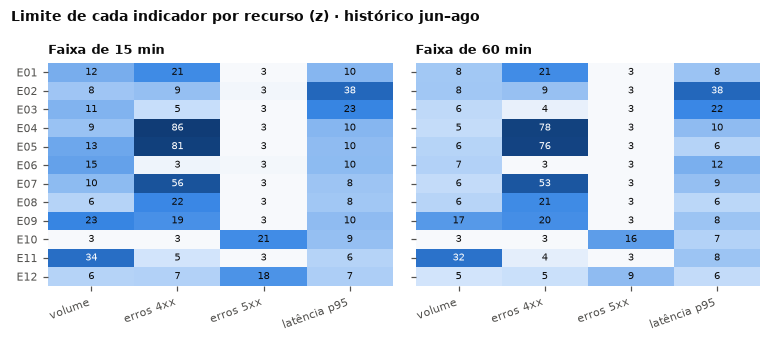

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.1), sharey=True)
for ax, L in zip(axes, (15, 60)):
    v = lim[L]
    ax.imshow(np.log10(v.to_numpy()), cmap=CMAP_SEQ, vmin=np.log10(3), vmax=2, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            ax.text(j, i, f"{v.iat[i, j]:.0f}", ha="center", va="center", fontsize=6.3,
                    color="white" if np.log10(v.iat[i, j]) > 1.45 else TXT1)
    ax.set_xticks(range(v.shape[1]))
    ax.set_xticklabels(v.columns, rotation=20, ha="right")
    ax.set_yticks(range(v.shape[0]))
    ax.set_yticklabels(v.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"Faixa de {L} min", loc="left")
fig.suptitle("Limite de cada indicador por recurso (z) · histórico jun–ago", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout()
salvar(fig, "fig_limites")
plt.show()

## Limites com histórico de 3 meses × 1 mês (setembro, 15 min)
Razão entre o limite com 3 meses e com 1 mês. Valores > 1: o histórico longo inclui mais picos (ou mudanças de patamar) e fica mais tolerante.

In [6]:
l3 = calib[(PROPOSTO, 15, "set", "3m")]["limite"]
l1 = calib[(PROPOSTO, 15, "set", "1m")]["limite"]
razao_lim = (l3 / l1).rename(index=rot).rename(columns=INDICADOR).sort_index()
print("razão mediana 3m/1m por indicador:", razao_lim.median().round(2).to_dict())
razao_lim.round(2)

razão mediana 3m/1m por indicador: {'volume': 0.82, 'erros 4xx': 1.1, 'erros 5xx': 1.0, 'latência p95': 0.98}


,volume,erros 4xx,erros 5xx,latência p95
E01,0.90,2.19,1.00,1.10
E02,0.81,1.67,0.84,1.89
E03,0.99,0.97,1.00,0.89
E04,0.41,1.01,1.00,0.90
E05,0.42,10.24,1.00,0.67
E06,0.94,0.95,1.05,1.32
E07,0.80,1.14,1.00,0.68
E08,0.84,1.06,1.00,0.74
E09,1.93,2.16,1.00,1.06
E10,0.26,1.00,0.95,1.22


## Alarmes no histórico (fora da amostra)

In [7]:
alarmes = {k: float((c["razao_cal"] > c["c"]).mean()) for k, c in calib.items()}
alarmes = pd.Series(alarmes).unstack([2, 3])
alarmes.round(4)

ago             set        
                                     3m      1m      3m      1m
Perfil contextual (proposto) 15  0.0308  0.0348  0.0344  0.0345
                             30  0.0309  0.0344  0.0340  0.0336
                             60  0.0306  0.0329  0.0330  0.0328
Semana anterior              15  0.0315  0.0334  0.0346  0.0325
                             30  0.0303  0.0329  0.0343  0.0323
                             60  0.0306  0.0334  0.0346  0.0341
z-score global               15  0.0287  0.0305  0.0316  0.0297
                             30  0.0296  0.0296  0.0318  0.0293
                             60  0.0279  0.0268  0.0291  0.0286

## Residual real no histórico (60 min, proposto, setembro/3 meses): qual indicador?

In [8]:
per = periodo_treino("set", HIST_PRINCIPAL)
cal = calib[(PROPOSTO, 60, "set", HIST_PRINCIPAL)]
p = recortar(periodos[60], per)
tr1h = recortar(jan1h, per)
dobra_p, dobra_1h = dobras(p, per), dobras(tr1h, per)
vezes = pd.DataFrame(index=p.index, columns=ATRIBUTOS, dtype=float)
for k in range(4):
    m = Perfil().ajustar(tr1h[dobra_1h != k])
    vezes.loc[dobra_p == k] = (z_direcional(m.z(p[dobra_p == k])) / cal["limite"].reindex(p.loc[dobra_p == k, "recurso"]).to_numpy()).to_numpy()
res = (vezes > 1).any(axis=1)
ind = vezes[res].astype(float).idxmax(axis=1).map(INDICADOR)
print(f"{int(res.sum())} períodos residuais de 1 h em jun–ago ({res.mean():.1%})")
ind.value_counts()

693 períodos residuais de 1 h em jun–ago (3.3%)


latência p95    201
volume          200
erros 4xx       191
erros 5xx       101
Name: count, dtype: int64

In [9]:
with open(RESULTADOS / "04_calibracao.pkl", "wb") as f:
    pickle.dump(calib, f)
pd.concat(lim, axis=1).to_csv(RESULTADOS / "04_limites.csv")
razao_lim.to_csv(RESULTADOS / "04_razao_limites_3m_1m.csv")
alarmes.to_csv(RESULTADOS / "04_alarmes_historico.csv")
salvar_json({" | ".join(map(str, k)): round(c["c"], 3) for k, c in calib.items()}, "04_multiplicadores.json")
salvar_json(dict(residuais_60=int(res.sum()), frac=float(res.mean()), indicadores=ind.value_counts().to_dict(),
                 razao_lim_mediana=razao_lim.median().to_dict()), "04_resumo.json")